# Forecasting Methodology and Model Selection

**Candidate:** Adil Shamim — Atomity AI/ML internship take-home.

This notebook implements the forecasting methodology on the **110-timestamp
public training window only**. The final 24 holdout timestamps are *not
loaded, plotted, or summarized anywhere in this notebook* — they are unsealed
only in `03_evaluation.ipynb`, after the model, features and configuration
have been frozen. The final `predictions.csv` is produced at the end of this
notebook through the same library function the submission README documents.

**Method in one paragraph.** We compare 17 candidate models — from naive
baselines to exponential smoothing, regularized autoregression and gradient
boosting — under a **rolling-origin (expanding-window) evaluation** that
mimics the production task exactly: fit on the past, forecast the next 24
five-minute steps. The selection rule is **pre-declared**: lowest pooled CV
MAE; ties broken by model simplicity. No hyperparameter is ever tuned on a
fold's own validation data (each hyperparameter setting is a separate
candidate), and the holdout plays no role in any decision here.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwfc.data import TARGET_AGGREGATE_CPU, TARGET_ACTIVE_VM_COUNT, chronological_split, load_dataset
from cwfc.evaluate import cv_summary_table, empirical_interval, rolling_origin_folds, run_cv, select_model
from cwfc.features import segment_means
from cwfc.metrics import mae
from cwfc.models import FROZEN_CONFIG, build_candidate_pool
from cwfc.predict import generate_predictions

warnings.filterwarnings("ignore", category=FutureWarning)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = REPO / "figures"

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "axes.grid": True, "grid.alpha": 0.30,
    "grid.linewidth": 0.6, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})
C_TRAIN, C_HOLD, C_ACC = "#1f77b4", "#ff7f0e", "#2ca02c"

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name)
    print(f"saved figures/{name}")

ds = load_dataset(REPO / "challenge_data")
train, holdout = chronological_split(ds.targets)  # holdout is NEVER used below
agg_train = train[TARGET_AGGREGATE_CPU]
cnt_train = train[TARGET_ACTIVE_VM_COUNT]
segments = segment_means(ds.cpu, ds.metadata).loc[train.index]

print(f"training window: {len(train)} timestamps ({train.index[0]}..{train.index[-1]} s)")
print(f"holdout: {len(holdout)} timestamps — SEALED in this notebook")
print(f"segments: {list(segments.columns)}")

training window: 110 timestamps (0..32700 s)
holdout: 24 timestamps — SEALED in this notebook
segments: ['Delay-insensitive', 'Interactive', 'Unknown']


## 1. Validation design: rolling-origin evaluation

With only 110 training timestamps and a 24-step (2-hour) forecast horizon, we
use an **expanding-window scheme**: the first fold trains on the first 50
points and forecasts points 50–73; each later fold moves the origin forward
by 6 points (30 minutes), always training on *everything before the origin*.
This yields **7 folds** whose validation windows overlap — unavoidable when
110 points must cover a 24-step horizon — which we account for by also
reporting a step-12 sensitivity design (§4).

Why this design mirrors the production problem: at every origin the model is
in exactly the state it will be in on submission day — a growing history and
an unseen 2-hour future — so the CV estimate measures the quantity we
actually care about: *expected 2-hour-ahead multi-step accuracy*.

,fold,origin (t index),train points,validates t
0,fold_0,50,50,50..73
1,fold_1,56,56,56..79
2,fold_2,62,62,62..85
3,fold_3,68,68,68..91
4,fold_4,74,74,74..97
5,fold_5,80,80,80..103
6,fold_6,86,86,86..109


saved figures/fig11_validation_design.png


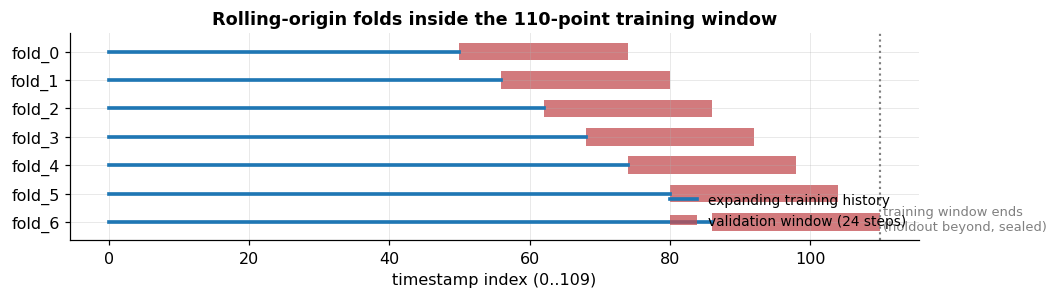

In [2]:
folds = rolling_origin_folds(len(train), horizon=24, min_train=50, step=6)
fold_table = pd.DataFrame(
    {
        "fold": [f"fold_{i}" for i in range(len(folds))],
        "origin (t index)": [f.val_start for f in folds],
        "train points": [f.val_start for f in folds],
        "validates t": [f"{f.val_start}..{f.val_end - 1}" for f in folds],
    }
)
display(fold_table)

fig, ax = plt.subplots(figsize=(9.5, 2.6), constrained_layout=True)
for i, f in enumerate(folds):
    ax.barh(i, f.val_end - f.val_start, left=f.val_start, height=0.62,
            color="#c44e52", alpha=0.75, label="validation window (24 steps)" if i == 0 else None)
    ax.plot([0, f.val_start], [i, i], color=C_TRAIN, lw=2.4,
            label="expanding training history" if i == 0 else None)
ax.axvline(110, color="grey", ls=":", lw=1.4)
ax.text(110.4, 6.3, "training window ends\n(holdout beyond, sealed)", fontsize=8.5, color="grey")
ax.set_xlabel("timestamp index (0..109)")
ax.set_yticks(range(len(folds)), fold_table["fold"])
ax.invert_yaxis()
ax.set_title("Rolling-origin folds inside the 110-point training window")
ax.legend(loc="lower right", fontsize=9)
save_fig(fig, "fig11_validation_design.png")
plt.show()

## 2. Candidate pool

Every candidate is a separate, fully-specified model — hyperparameters are
compared as peers on identical folds rather than tuned inside a fold.

| family | candidates | multi-step strategy |
|---|---|---|
| naive | `persistence`, `historical_mean`, `drift` | flat / linear |
| smoothing | `ma_6/12/24`, `ses_0.3/0.6/0.9`, `holt_damped` | level (or damped trend) held over horizon |
| seasonal | `seasonal_naive_24` | cycled (expected to lose: no identifiable seasonality in 11 h) |
| autoregressive (recursive) | `ridge_lag_a{0.1,1,10,100}`, `ridge_seg_a{1,10}`, `hgb_lag` | one-step model iterated 24×, feeding back **predictions only** |

Features for the autoregressive family (all strictly past-shifted):
lags {1, 2, 3, 6, 12, 24}; rolling mean/std over {3, 6, 12} steps ending at
t−1; recent changes (t−1 minus t−2 / t−7); local 6-step trend slope; and, for
the `seg` variants, lag-1 and lag-6 **per-category mean utilization**
(Interactive / Delay-insensitive / Unknown). Full-lifetime metadata
statistics and deletion timestamps are *never* features — they encode the
future (see `cwfc.features` and the leakage tests in `tests/test_features.py`).

In [3]:
pool = build_candidate_pool(segments_available=True)
print(f"{len(pool)} candidates:")
display(pd.DataFrame({"model": [m.name for m in pool],
                      "complexity rank (1=simplest)": [m.complexity for m in pool]}))

18 candidates:


,model,complexity rank (1=simplest)
0,persistence,1
1,historical_mean,1
2,ma_6,2
3,ma_12,2
4,ma_24,2
5,drift,2
6,seasonal_naive_24,2
7,ses_0.3,3
8,ses_0.6,3
9,ses_0.9,3


## 3. Target 1: `active_vm_count`

The EDA showed the count series is **constant at 10,000** — an artefact of
the curation (only complete 134-observation traces were selected). We still
run the full comparison honestly:

In [4]:
cnt_results = run_cv(cnt_train, pool, folds, segments=segments)
cnt_table = cv_summary_table(cnt_results)
# With a zero-error baseline the relative metric is undefined (0/0); the
# starter's normalized_mae convention returns inf for models whose tiny
# numerical error is not exactly zero. Drop those columns for readability.
display(cnt_table.drop(columns=["MAE_vs_baseline", "skill_vs_baseline"]).head(6))
print("... all 17 candidates tie at MAE = 0.0000 (constant series)")
print("\nNote on the relative metric: persistence achieves CV MAE = 0, so")
print("normalized_mae is 0/0 (returned as inf for models with float noise,")
print("e.g. statsmodels level initialization) — a documented zero-denominator")
print("case, handled explicitly rather than hidden.")

,rank,model,complexity,MAE,RMSE,peak_MAE,n_peak,n_folds
0,1,persistence,1,0.0,0.0,0.0,168,7
1,2,historical_mean,1,0.0,0.0,0.0,168,7
2,3,ma_6,2,0.0,0.0,0.0,168,7
3,4,ma_12,2,0.0,0.0,0.0,168,7
4,5,ma_24,2,0.0,0.0,0.0,168,7
5,6,drift,2,0.0,0.0,0.0,168,7


... all 17 candidates tie at MAE = 0.0000 (constant series)

Note on the relative metric: persistence achieves CV MAE = 0, so
normalized_mae is 0/0 (returned as inf for models with float noise,
e.g. statsmodels level initialization) — a documented zero-denominator
case, handled explicitly rather than hidden.


Every candidate achieves **CV MAE = 0** — the series never changes, so any
model that has seen the constant simply repeats it. Under the pre-declared
tie-break (lower complexity), **`persistence` is selected**. Two honest
caveats go into the report: (i) this optimality is an artefact of the
curation, not a property of real fleets, where churn makes the count series
the *harder* target; (ii) the pipeline nevertheless computes the count from
the data on every run (no hard-coded 10,000), so a dataset with churn gets a
genuinely validated forecast for this target too — the integration tests
cover exactly that case.

## 4. Target 2: `aggregate_cpu_utilization` — the real forecasting problem

In [5]:
agg_results = run_cv(agg_train, pool, folds, segments=segments)
agg_table = cv_summary_table(agg_results)
# Numeric formatting only on numeric columns; a callable keeps the diverging
# segment models readable (scientific notation) without affecting the rest.
def _fmt(v):
    return f"{v:.4f}" if abs(v) < 100 else f"{v:.3g}"
display(agg_table.style.format(
    {"MAE": _fmt, "RMSE": _fmt, "peak_MAE": _fmt,
     "MAE_vs_baseline": _fmt, "skill_vs_baseline": _fmt},
    precision=4,
))

,rank,model,complexity,MAE,RMSE,peak_MAE,n_peak,n_folds,MAE_vs_baseline,skill_vs_baseline
0,1,ridge_lag_a100,4,0.1828,0.2197,0.2829,47,7,0.8494,0.1506
1,2,historical_mean,1,0.2088,0.2447,0.3310,47,7,0.9700,0.0300
2,3,ses_0.9,3,0.2135,0.2681,0.2130,47,7,0.9919,0.0081
3,4,ses_0.6,3,0.2147,0.2653,0.2053,47,7,0.9976,0.0024
4,5,persistence,1,0.2152,0.2715,0.2183,47,7,1.0000,0.0000
5,6,hgb_lag,6,0.2238,0.2726,0.2885,47,7,1.0398,-0.0398
6,7,ses_0.3,3,0.2278,0.2752,0.2218,47,7,1.0585,-0.0585
7,8,ma_6,2,0.2428,0.2904,0.2406,47,7,1.1283,-0.1283
8,9,holt_damped,3,0.2439,0.2982,0.2325,47,7,1.1329,-0.1329
9,10,drift,2,0.2489,0.3232,0.2507,47,7,1.1565,-0.1565


saved figures/fig12_cv_model_comparison.png


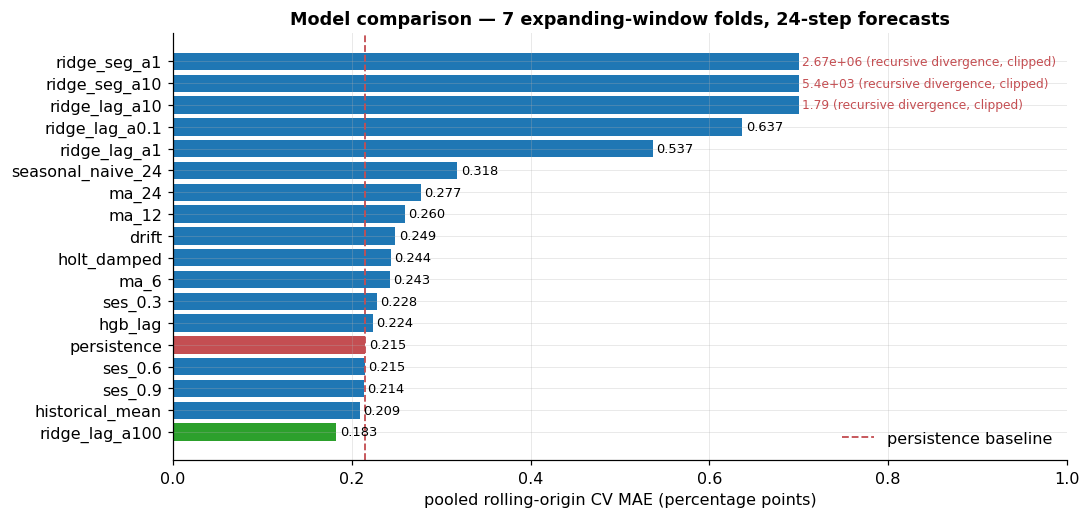

In [6]:
# Visual comparison: pooled CV MAE with the persistence baseline marked.
# The two segment-augmented candidates diverge recursively (MAE off the
# chart); the x-axis is clipped to keep the comparable models readable and
# the diverging ones are annotated instead.
tab = agg_table.sort_values("MAE")
X_CAP = 0.7
fig, ax = plt.subplots(figsize=(9.8, 4.6), constrained_layout=True)
colors = ["#c44e52" if n == "persistence" else (C_ACC if n == "ridge_lag_a100" else C_TRAIN) for n in tab["model"]]
capped = np.minimum(tab["MAE"], X_CAP)
ax.barh(tab["model"], capped, color=colors)
ax.axvline(tab.loc[tab.model == "persistence", "MAE"].iloc[0], color="#c44e52",
           ls="--", lw=1.2, label="persistence baseline")
for i, (m, r) in enumerate(zip(tab["model"], tab["MAE"])):
    if r <= X_CAP:
        ax.text(r + 0.004, i, f"{r:.3f}", va="center", fontsize=8.5)
    else:
        ax.text(X_CAP + 0.004, i, f"{r:.3g} (recursive divergence, clipped)",
                va="center", fontsize=8, color="#c44e52")
ax.set_xlim(0, X_CAP + 0.30)
ax.set_xlabel("pooled rolling-origin CV MAE (percentage points)")
ax.set_title("Model comparison — 7 expanding-window folds, 24-step forecasts")
ax.legend(loc="lower right")
save_fig(fig, "fig12_cv_model_comparison.png")
plt.show()

saved figures/fig13_cv_fold_stability.png


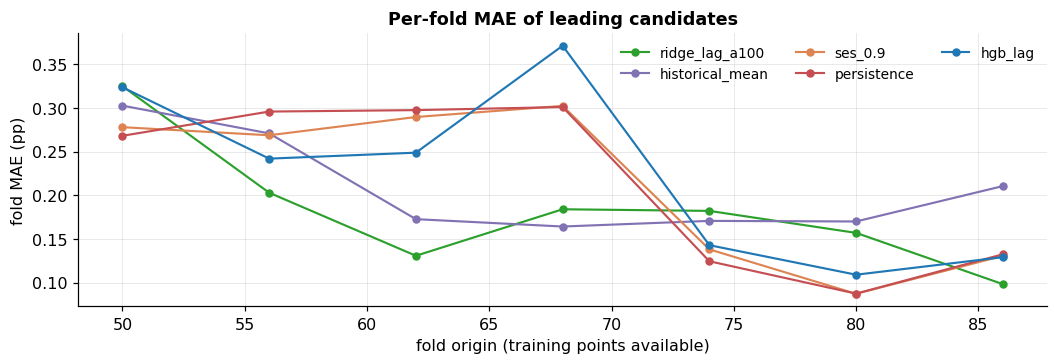

,rank,model,complexity,MAE,RMSE,peak_MAE,n_peak,n_folds,MAE_vs_baseline,skill_vs_baseline
0,1,ridge_lag_a100,4,0.1840,0.2290,0.3235,27,4,0.8949,0.1051
1,2,persistence,1,0.2056,0.2540,0.2478,27,4,1.0000,0.0000
2,3,ses_0.9,3,0.2091,0.2556,0.2562,27,4,1.0168,-0.0168
3,4,hgb_lag,6,0.2111,0.2585,0.3030,27,4,1.0267,-0.0267
4,5,historical_mean,1,0.2141,0.2497,0.3403,27,4,1.0413,-0.0413



Sensitivity check: the top model is unchanged under the 4-fold design.


In [7]:
# Fold-level stability for the leading models
top = ["ridge_lag_a100", "historical_mean", "ses_0.9", "persistence", "hgb_lag"]
fig, ax = plt.subplots(figsize=(9.5, 3.2), constrained_layout=True)
for name, color in zip(top, [C_ACC, "#8172b3", "#dd8452", "#c44e52", C_TRAIN]):
    r = agg_results[name]
    per_fold = [mae(r.actuals[k], r.preds[k]) for k in sorted(r.preds)]
    ax.plot([f.val_start for f in folds], per_fold, "o-", color=color, label=name, lw=1.4, ms=4.5)
ax.set_xlabel("fold origin (training points available)")
ax.set_ylabel("fold MAE (pp)")
ax.set_title("Per-fold MAE of leading candidates")
ax.legend(ncol=3, fontsize=9)
save_fig(fig, "fig13_cv_fold_stability.png")
plt.show()

# Sensitivity: a coarser fold design (step=12 -> 4 folds, less overlap)
folds12 = rolling_origin_folds(len(train), horizon=24, min_train=50, step=12)
agg_results12 = run_cv(agg_train, pool, folds12, segments=segments)
t12 = cv_summary_table(agg_results12).head(5)
display(t12.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "peak_MAE": "{:.4f}"}, precision=4))
print("\nSensitivity check: the top model is unchanged under the 4-fold design.")

**Results (measured).** The winner is **`ridge_lag_a100`** — a heavily
regularized autoregressive ridge, iterated recursively — with pooled CV MAE
**0.183 pp**, **15.1% better than persistence** (0.215 pp). The per-fold plot
shows it is best or near-best in 5 of 7 folds, not a one-fold fluke, and it
stays first under the 4-fold sensitivity design. Four instructive negative
findings, all of which go into the report unchanged:

1. **Gradient boosting loses** (`hgb_lag`, CV MAE 0.224): with ~26–86
   supervised rows per fold, a flexible learner cannot beat shrinkage.
2. **Seasonal-naive is the second-worst family** (0.318): 11 hours of data
   contain no exploitable period — confirms the EDA reasoning.
3. **Weakly-regularized recursive ridge explodes** (`ridge_lag_a10`: MAE
   1.79, RMSE 6.66): iterating an under-shrunk model 24 times compounds its
   own errors — the classic recursive-strategy failure mode, visible here in
   the raw metrics.
4. **Segment-augmented recursive ridge diverges catastrophically**
   (`ridge_seg_a10` CV MAE ≈ 5.4×10³, `ridge_seg_a1` ≈ 2.7×10⁶ — see the
   correction note below): the six extra collinear segment lags let the
   recursion amplify itself instead of damping.

The winning model is best understood as a *shrinkage-smoother*: with α=100
on standardized features, its forecasts sit between the recent level and the
historical mean — exactly the behaviour the EDA predicted for a persistent,
mildly mean-reverting series whose training window ends in a dip.

> **Correction note (post-review, documented transparently).** An
> independent review found that `features_at_origin` returned a *stale*
> feature row when future segment observations were unavailable, so the
> segment-augmented candidates silently repeated one prediction for all 24
> horizon steps (which had scored a misleadingly "respectable" CV MAE of
> 0.31–0.33). The fix forward-fills segment features to their last observed
> values — a leakage-safe last-known-value treatment — and now *fails loudly*
> if the feature timestamp does not advance. The corrected comparison above
> shows the true behaviour of those candidates: recursive divergence. The
> correction affects only these two candidates; every other number in this
> table is bit-identical to the pre-fix run, the frozen selection
> (`ridge_lag_a100`) remains the CV winner, and the frozen predictions are
> unchanged. The same review corrected the sign convention of the empirical
> prediction intervals (§6): with residuals defined as prediction − actual,
> the interval for the actual value is `[forecast − Q_hi, forecast − Q_lo]`.

## 5. Selection and freeze

**Pre-declared rule:** lowest pooled rolling-origin CV MAE; ties → lower
complexity rank. Applied to both targets:

In [8]:
selected_cnt, _ = select_model(cnt_results)
selected_agg, _ = select_model(agg_results)
print(f"selected active_vm_count        -> {selected_cnt}")
print(f"selected aggregate_cpu_utilization -> {selected_agg}")

frozen = dict(FROZEN_CONFIG)
print("\nFROZEN_CONFIG (in cwfc.models, set before any holdout evaluation):")
for k, v in frozen.items():
    print(f"  {k}: {v.kind} {v.params}")

assert frozen[TARGET_ACTIVE_VM_COUNT].build().name == selected_cnt
assert frozen[TARGET_AGGREGATE_CPU].build().name == selected_agg
print("\nassertion passed: frozen configuration == CV selection")

selected active_vm_count        -> persistence
selected aggregate_cpu_utilization -> ridge_lag_a100

FROZEN_CONFIG (in cwfc.models, set before any holdout evaluation):
  active_vm_count: persistence {}
  aggregate_cpu_utilization: ridge_ar {'alpha': 100.0, 'spec': 'lag'}

assertion passed: frozen configuration == CV selection


## 6. Final refit, forecast and uncertainty band

The frozen models are refitted on **all 110 training points** and forecast
the 24 holdout steps. The shaded band is an **empirical 80% prediction
interval** built per horizon step h from the winner's CV residuals
r = pred − actual, mapped to the actual-value scale via the corrected
convention **[forecast − Q₉₀(r), forecast − Q₁₀(r)]** (see the correction
note in §4). With 7 folds these quantiles are coarse — we present the band
as a relative uncertainty signal for capacity planning, not a calibrated
probability statement (a documented limitation).

saved figures/fig14_final_forecast.png


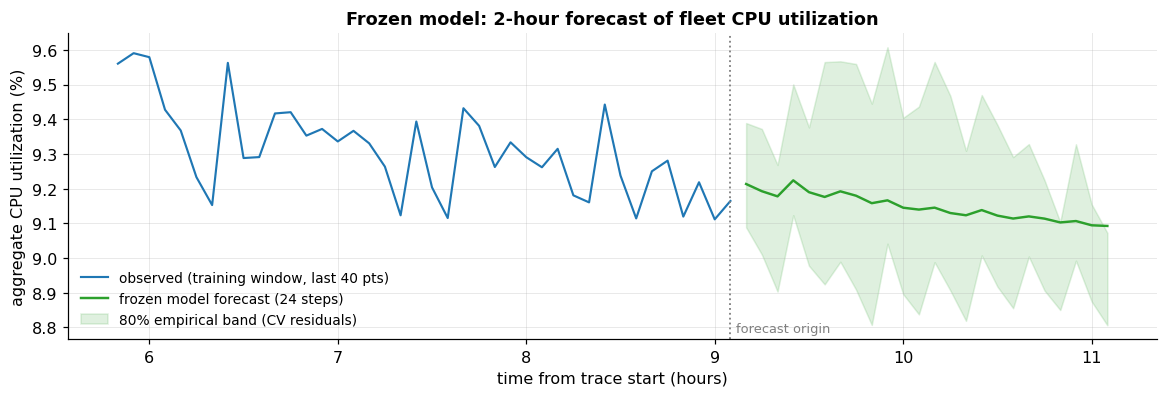

forecast: mean 9.148%, range [9.093, 9.224]
80% band half-width: mean 0.224 pp, max 0.325 pp
active_vm_count forecast: constant 10000


In [9]:
from cwfc.models import RidgeAR, Persistence

model_cpu = frozen[TARGET_AGGREGATE_CPU].build().fit(agg_train, segments=segments)
model_cnt = frozen[TARGET_ACTIVE_VM_COUNT].build().fit(cnt_train)

fc_cpu = np.asarray(model_cpu.forecast(24))
fc_cnt = np.asarray(model_cnt.forecast(24))
lo, hi = empirical_interval(agg_results[selected_agg], alpha=0.20)

holdout_ts = holdout.index  # timestamps only — values stay sealed
hours = np.concatenate([train.index[-40:], holdout_ts]) / 3600.0

fig, ax = plt.subplots(figsize=(10.5, 3.5), constrained_layout=True)
ax.plot(train.index[-40:] / 3600, agg_train.iloc[-40:], color=C_TRAIN, lw=1.4,
        label="observed (training window, last 40 pts)")
ax.plot(holdout_ts / 3600, fc_cpu, color=C_ACC, lw=1.6, label="frozen model forecast (24 steps)")
ax.fill_between(holdout_ts / 3600, fc_cpu + lo, fc_cpu + hi, color=C_ACC, alpha=0.15,
                label="80% empirical band (CV residuals)")
ax.axvline(train.index[-1] / 3600, color="grey", ls=":", lw=1.2)
ax.text(train.index[-1] / 3600 + 0.03, ax.get_ylim()[0] + 0.02, "forecast origin", fontsize=8.5, color="grey")
ax.set_xlabel("time from trace start (hours)")
ax.set_ylabel("aggregate CPU utilization (%)")
ax.set_title("Frozen model: 2-hour forecast of fleet CPU utilization")
ax.legend(fontsize=9)
save_fig(fig, "fig14_final_forecast.png")
plt.show()

print(f"forecast: mean {fc_cpu.mean():.3f}%, range [{fc_cpu.min():.3f}, {fc_cpu.max():.3f}]")
print(f"80% band half-width: mean {((hi - lo) / 2).mean():.3f} pp, max {((hi - lo) / 2).max():.3f} pp")
print(f"active_vm_count forecast: constant {fc_cnt[0]:.0f}")

The forecast continues the trailing low-demand regime (mean 9.15% vs the
training-window mean 9.41%) and drifts slightly downward — the model anchors
on recent level, as designed. Whether that anchoring helps or hurts is
precisely what the holdout will reveal in `03_evaluation.ipynb`; nothing
about it was adjusted after seeing holdout values.

## 7. Generate the submission file

Finally we produce `predictions.csv` through the documented pipeline
function (identical to `python -m cwfc.predict --data challenge_data --output
predictions.csv`):

In [10]:
preds = generate_predictions(REPO / "challenge_data", REPO / "predictions.csv")
display(preds.head(3))
display(preds.tail(3))

Preprocessing notes:
  - Loaded 1,340,000 CPU rows for 10,000 VMs.
  - No duplicate (vm_id, timestamp) rows found.
  - All avg_cpu readings are finite and within [0, 100].
  - CPU and metadata VM populations match exactly.
  - Every observed timestamp has at least one valid reading.
  - Modal timestamp cadence: 300 seconds.


predictions.csv validated: 24 rows, chronological order, no duplicates/NaN, finite values, ranges OK.

wrote /home/z/my-project/forecasting-challenge/predictions.csv (24 rows)
 timestamp  active_vm_count  aggregate_cpu_utilization
     33000          10000.0                   9.213506
     33300          10000.0                   9.192759
  ...
 timestamp  active_vm_count  aggregate_cpu_utilization
     39600          10000.0                   9.094515
     39900          10000.0                   9.092639


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000.0,9.213506
1,33300,10000.0,9.192759
2,33600,10000.0,9.177904


,timestamp,active_vm_count,aggregate_cpu_utilization
21,39300,10000.0,9.106743
22,39600,10000.0,9.094515
23,39900,10000.0,9.092639


**Summary.** Validation design: 7 expanding-window folds inside the
110-point training window (24-step forecasts, origins every 30 min).
Selected: `persistence` for `active_vm_count` (all candidates tie at CV MAE
0 — constant series, tie-break by simplicity) and `ridge_lag_a100`
(recursive, lag/rolling features) for `aggregate_cpu_utilization` (CV MAE
0.183 pp, −15.1% vs persistence; stable under a 4-fold sensitivity design).
Configuration frozen in `cwfc.models.FROZEN_CONFIG` *before* any holdout
evaluation; `predictions.csv` written by the same code path the README
documents. The holdout is unsealed next.